<a href="https://colab.research.google.com/github/sebassanchez5680-tech/Prueba/blob/main/271757_OP_Hiperparametro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1. Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

Declarar las bibliotecas necesarias para este proyecto
Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features. Se puede descargar de https://archive.ics.uci.edu/dataset/759/glioma+grading+clinical+and+mutation+features+dataset

In [20]:
#!pip install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import LabelEncoder
import warnings

glioma_grading = fetch_ucirepo(id=759) #Id 759
X = glioma_grading.data.features
y = glioma_grading.data.targets

df = pd.concat([X, y], axis=1)
label_encoders = {}
for column in df.select_dtypes(include=['object']).columns:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column].astype(str))
    label_encoders[column] = le

X = df.drop(y.columns[0], axis=1) #reasignar X y Y
y = df[y.columns[0]]

##2. 📊 Análisis exploratorio de datos (EDA)

Realiza un análisis inicial de los datos antes de modelar:

Describir forma y estructura (shape, describe(), info()).

Mostrar la distribución de clases (y.value_counts()).

Visualizar:

Histograma de al menos 3 variables numéricas.

Boxplots o violin plots por clase si es computacionalmente viable.

Mapa de calor de correlaciones entre variables.

Shape del dataset: (839, 24)
Informacion del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839 entries, 0 to 838
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Gender            839 non-null    int64  
 1   Age_at_diagnosis  839 non-null    float64
 2   Race              839 non-null    int64  
 3   IDH1              839 non-null    int64  
 4   TP53              839 non-null    int64  
 5   ATRX              839 non-null    int64  
 6   PTEN              839 non-null    int64  
 7   EGFR              839 non-null    int64  
 8   CIC               839 non-null    int64  
 9   MUC16             839 non-null    int64  
 10  PIK3CA            839 non-null    int64  
 11  NF1               839 non-null    int64  
 12  PIK3R1            839 non-null    int64  
 13  FUBP1             839 non-null    int64  
 14  RB1               839 non-null    int64  
 15  NOTCH1            839 non-null    int

,Gender,Age_at_diagnosis,Race,IDH1,TP53,ATRX,PTEN,EGFR,CIC,MUC16,...,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA,Grade
count,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,...,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000,839.000000
mean,0.418355,50.935411,2.892729,0.481526,0.414779,0.258641,0.168057,0.133492,0.132300,0.116806,...,0.047676,0.045292,0.034565,0.032181,0.032181,0.032181,0.027414,0.027414,0.026222,0.419547
std,0.493583,15.702339,0.369392,0.499957,0.492978,0.438149,0.374140,0.340309,0.339019,0.321380,...,0.213206,0.208068,0.182784,0.176586,0.176586,0.176586,0.163383,0.163383,0.159889,0.493779
min,0.000000,14.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,38.055000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,51.550000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,62.800000,3.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,1.000000,89.290000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



Distribucion de clases en el target:
Grade
0    487
1    352
Name: count, dtype: int64


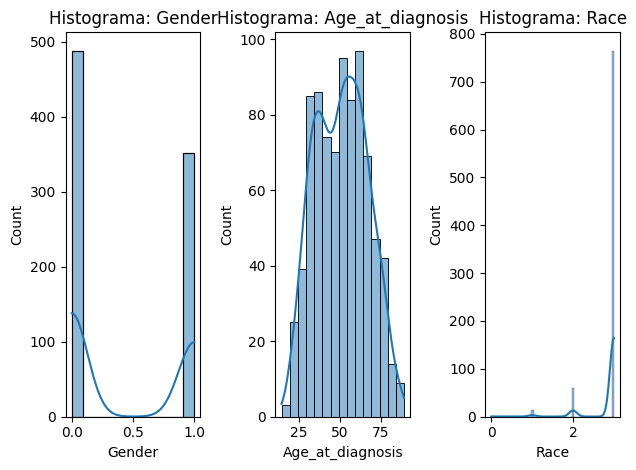

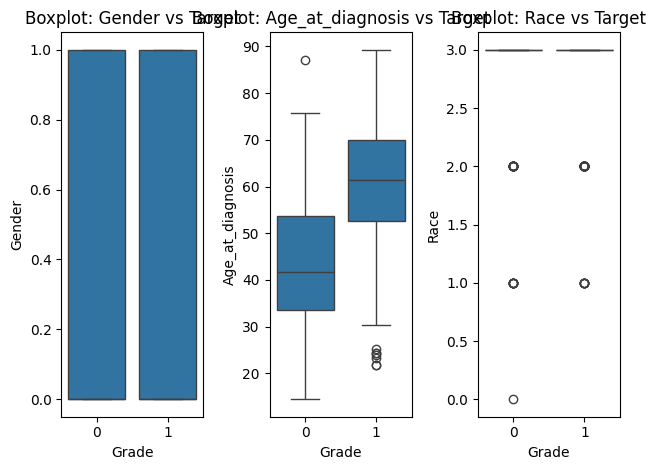

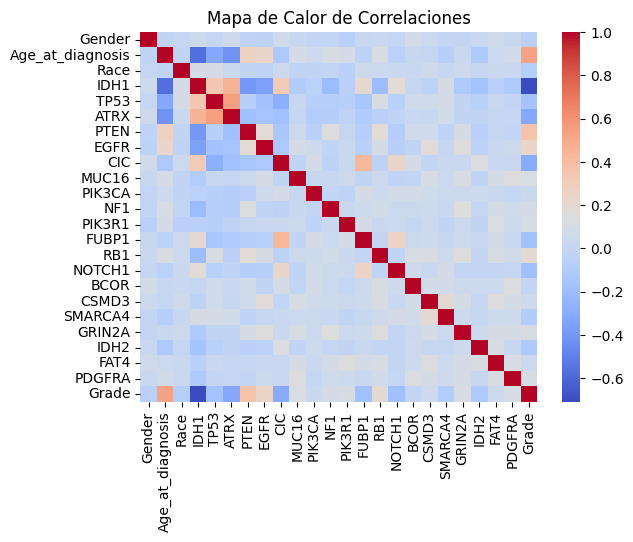

In [14]:
# Describir forma y estructura
print("Shape del dataset:", df.shape)
print("Informacion del dataset:")
df.info()
print("Estadisticas descriptivas:")
display(df.describe())
print("\nDistribucion de clases en el target:")
print(y.value_counts())
num_vars = X.columns[:3]

for i, col in enumerate(num_vars, 1): #histogramas
    plt.subplot(1, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(f'Histograma: {col}')
plt.tight_layout()
plt.show()

for i, col in enumerate(num_vars, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(x=y, y=df[col]) #Boxplot
    plt.title(f'Boxplot: {col} vs Target')
plt.tight_layout()
plt.show()

sns.heatmap(df.corr(), annot=False, cmap='coolwarm') #mapa de calor correlaciones
plt.title('Mapa de Calor de Correlaciones')
plt.show()

¿Existen clases desbalanceadas?

 Al observar y.value_counts(), los gliomas suelen presentar un grado de desbalance (por ejemplo, diferencias entre Glioblastoma y grados inferiores -LGG vs GBM-). Si el desbalance es notable, el uso de métricas como F1 Macro está plenamente justificado, ya que penaliza el mal rendimiento en la clase minoritaria.

¿Qué atributos parecen más informativos?

En el mapa de calor aquellos atributos que presentan mayor coeficiente de correlacion (colores más oscuros) con la variable objetivo son los mas informativos, porque se ven afectados mas ante los cambios.

##3. Gráfica de Errores en Entrenamiento y Prueba

En este ejercicio vas a entrenar un árbol de decisión con diferentes profundidas. Asimismo, en gráfica mostrarás las exactitudes en entrenamiento y test, usando un stratified k-fold cross-validation con K= 10
Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None
Deberás usar StratifiedKFold con 10 particiones, y un valor aleaotorio de 3
Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades
Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro",y el StratifiedKFold, con un valor aleatorio = 7
Muestra una fráfica para los distintos resultados  cuando se usa F1 Macro

F1 Macro Scores promedio por profundidad: [np.float64(0.8665382801612596), np.float64(0.8577161133334261), np.float64(0.8239221627884092), np.float64(0.7927086488626973), np.float64(0.7850889213350664), np.float64(0.7940747109538426), np.float64(0.7938963851997338), np.float64(0.7938963851997338)]


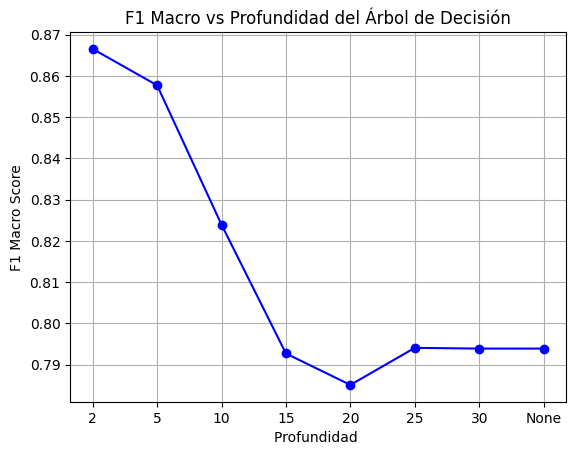

In [15]:
depths = [2, 5, 10, 15, 20, 25, 30, None]
cv_scores_mean = []

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=3) #10 particiones y valor aleatorio de 3

for depth in depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=7) #valor aleatorio 7
    scores = cross_val_score(dt, X, y, cv=skf, scoring='f1_macro', n_jobs=-1)
    cv_scores_mean.append(scores.mean())

print("F1 Macro Scores promedio por profundidad:", cv_scores_mean)

depths_str = [str(d) for d in depths]
plt.plot(depths_str, cv_scores_mean, marker='o', linestyle='-', color='b')
plt.title('F1 Macro vs Profundidad del Árbol de Decisión')
plt.xlabel('Profundidad ')
plt.ylabel('F1 Macro Score')
plt.grid(True)
plt.show()

##4. Optimización de hiperparámetros con RandomizedSearchCV

Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
Criterion = gini ,entropy
max_depth: de 5 a 50 con incrementos de 1
min_samples_split: de 2 a 20 con incrementos de 1
Usa el árbol de decisión
StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
n_iter = 5 (combinaciones aleatorias a buscar)
n_jobs = -1 para acelerar cómputo
Métrica de evaluación: f1 Macro
Imprime los mejores hiperparámetros encontrados
Imprime el best_score

In [16]:
param_dist = {'criterion': ['gini', 'entropy'],'max_depth': np.arange(5, 51, 1),'min_samples_split': np.arange(2, 21, 1)}
dt = DecisionTreeClassifier(random_state=7)
skf_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)
random_search_f1 = RandomizedSearchCV(dt, param_distributions=param_dist, n_iter=5, cv=skf_10, scoring='f1_macro', n_jobs=-1, random_state=7)
random_search_f1.fit(X, y)

print("Mejores hiperparametros:", random_search_f1.best_params_)
print("Best Score:", random_search_f1.best_score_)

Mejores hiperparametros: {'min_samples_split': np.int64(9), 'max_depth': np.int64(43), 'criterion': 'entropy'}
Best Score: 0.824389460480314


##5. Optimización de hiperparámetros con GridSearchCV

Define el espacio de búsqueda  para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el

ejercicio considerando que es un conjunto de tamaño medio)

Métrica de evaluación: f1 Macro

n_jobs = -1 para acelerar cómputo

Imprime los mejores hiperparámetros encontrados

Imprime el best_score

In [17]:
param_grid = {'criterion': ['gini', 'entropy'],'max_depth': np.arange(5, 51, 1),'min_samples_split': np.arange(2, 21, 1)}
grid_search_f1 = GridSearchCV(dt, param_grid=param_grid, cv=skf_10, scoring='f1_macro', n_jobs=-1)
grid_search_f1.fit(X, y)

print("Mejores hiperparametros:", grid_search_f1.best_params_)
print("Best Score:", grid_search_f1.best_score_)

Mejores hiperparametros: {'criterion': 'entropy', 'max_depth': np.int64(6), 'min_samples_split': np.int64(13)}
Best Score: 0.8651160144238152


##6. Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

n_iter = 5 (combinaciones aleatorias a buscar)

n_jobs = -1 para acelerar cómputo

Métrica de evaluación: accuracy

Imprime los mejores hiperparámetros encontrados

Imprime el best_score


In [18]:
random_search_acc = RandomizedSearchCV(dt, param_distributions=param_dist, n_iter=5, cv=skf_10, scoring='accuracy', n_jobs=-1, random_state=7)
random_search_acc.fit(X, y)

print("Mejores hiperparámetros (RandomizedSearchCV - Accuracy):", random_search_acc.best_params_)
print("Best Score:", random_search_acc.best_score_)

Mejores hiperparámetros (RandomizedSearchCV - Accuracy): {'min_samples_split': np.int64(9), 'max_depth': np.int64(43), 'criterion': 'entropy'}
Best Score: 0.8307085484796326


##7. Optimización de hiperparámetros con GridSearchCV: accuracy

Define el espacio de búsqueda  para los siguientes hiperpárametros:

Criterion = gini ,entropy

max_depth: de 5 a 50 con incrementos de 1

min_samples_split: de 2 a 20 con incrementos de 1

Usa el árbol de decisión

StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)

Métrica de evaluación: f1 Macro

n_jobs = -1 para acelerar cómputo

Imprime los mejores hiperparámetros encontrados

Imprime el best_score

In [19]:
grid_search_acc = GridSearchCV(dt, param_grid=param_grid, cv=skf_10, scoring='accuracy', n_jobs=-1)
grid_search_acc.fit(X, y)

print("Mejores hiperparametros:", grid_search_acc.best_params_)
print("Best Score:", grid_search_acc.best_score_)

Mejores hiperparametros: {'criterion': 'entropy', 'max_depth': np.int64(5), 'min_samples_split': np.int64(13)}
Best Score: 0.8664515203671831


##8.Actividad de reflexión y análisis
###¿Cuál método encontró mejores hiperparámetros?

GridSearchCV encuentra los mejores hiperparametros dentro del espacio definido, logrando un score mas alto. Ya que prueba exhaustivamente todas las combinaciones posibles.

###¿Cuál fue más costoso computacionalmente?

GridSearchCV fue el mas costoso ademas del que mas tiempo le tomo imprimir los resultados. Evaluo miles de combinaciones 1,748 combinaciones (2 criterios × 46 profundidades × 19 splits), multiplicadas por 10 folds (17,480 total), mientras que Rav .

###¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?

Si fueron distintos, por que Gridsearchcv evaluo todo el grid buscando el valor que maximiza la metrica, mientras que Randomizedsearchcv solo probo 5 puntos aleatorios, por lo que parece depende mas de la suerte.

###¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?

Al igual que f1_macro. La busqueda exhaustiva de Grid por lo que garantiza el maximo accuracy dentro de los limites impuestos, a diferencia de la seleccion aleatoria de 5 iteraciones de la busqueda aleatoria.

###¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro?

Los de F1 fueron mas alto en el score, por lo que f1 predice mejor.